# 00 · Region lookup — attach `trust → region`

The RTT files carry each provider's **ICB** (`Provider Parent`) but **not** its NHS region. This
notebook resolves the missing tier authoritatively from the **NHS ODS ORD API** (the Spine
Organisation Data Service), then joins it back through the ICB we already have:

> **trust → ICB** (from the data) **→ region** (from ODS)

Each ICB record has an `RE2` relationship (role `RO209` = *NHS England Region*) pointing at one of
the **7 official regions**. We resolve the ~42 ICBs once, cache the result, and map every trust.

**Outputs:** `results/icb_region_lookup.csv`, `results/trust_region_lookup.csv` — the prerequisite
for **Step 4 (selection)**. Kernel: **FedOPD (.venv)**.

## Cell 1 — setup + most-recent ICB per trust

- Find the repo root, load the trust-only parquet.
- A trust's ICB label changed over the 61 months (CCG→ICB rename), so we take its **most recent**
  ICB (`'last'` after sorting by date) — the current one that ODS will recognise.

In [1]:
from pathlib import Path
import json, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_repo(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / 'src' / 'rtt.py').exists():
            return p
    raise FileNotFoundError('repo root not found')

REPO = find_repo()
RESULTS = Path.cwd() / 'results'; RESULTS.mkdir(exist_ok=True)
FIGS = REPO / 'reports' / 'figures'; FIGS.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(REPO / 'data' / 'processed' / 'rtt_trusts_canonical.parquet')
trusts = (df.sort_values('date').groupby('branch')
            .agg(branch_name=('branch_name', 'last'),
                 icb=('icb', 'last'), icb_name=('icb_name', 'last')).reset_index())
icbs = sorted(trusts['icb'].dropna().unique())
print(f'trusts {len(trusts)} | unique current ICBs {len(icbs)}')

trusts 172 | unique current ICBs 42


## Cell 2 — resolve ICB → region from ODS (cached)

- `ord_get(code)` fetches one organisation record from the ODS ORD API.
- For each ICB we read its `Rels`, find the active `RE2 / RO209` relationship, and take the region
  code (`Y56`…`Y63`).
- **Caching:** if `results/icb_region_lookup.csv` already exists we load it and skip the network,
  so re-runs are instant and offline. Delete that file to force a refresh.

In [2]:
CACHE = RESULTS / 'icb_region_lookup.csv'
API = 'https://directory.spineservices.nhs.uk/ORD/2-0-0/organisations/'

def ord_get(code):
    req = urllib.request.Request(API + code, headers={'Accept': 'application/json', 'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=30) as r:
        return json.load(r).get('Organisation', {})

def region_of(org):
    for rel in org.get('Rels', {}).get('Rel', []):
        pr = rel.get('Target', {}).get('PrimaryRoleId'); pr = pr.get('id') if isinstance(pr, dict) else pr
        if rel.get('id') == 'RE2' and pr == 'RO209' and rel.get('Status') == 'Active':
            return rel['Target']['OrgId']['extension']
    return None

if CACHE.exists():
    icb_map = pd.read_csv(CACHE)
    print('loaded cache:', CACHE.name)
else:
    rows = []
    for c in icbs:
        org = ord_get(c); rc = region_of(org)
        rows.append({'icb': c, 'icb_name_ods': org.get('Name'), 'region_code': rc})
        time.sleep(0.05)
    icb_map = pd.DataFrame(rows)
    # attach clean region names (query each region code once)
    names = {rc: ord_get(rc).get('Name') for rc in sorted(icb_map['region_code'].dropna().unique())}
    clean = lambda s: s.title().replace(' Commissioning Region', '').replace(' And ', ' and ').replace(' Of ', ' of ')
    icb_map['region'] = icb_map['region_code'].map(lambda rc: clean(names[rc]) if rc in names else None)
    icb_map.to_csv(CACHE, index=False)
    print('fetched + cached:', CACHE.name)

print('unresolved ICBs:', int(icb_map['region_code'].isna().sum()))
icb_map.head()

fetched + cached: icb_region_lookup.csv
unresolved ICBs: 0


,icb,icb_name_ods,region_code,region
0,D7T5G,NHS ESSEX INTEGRATED CARE BOARD,Y61,East of England
1,QE1,NHS LANCASHIRE AND SOUTH CUMBRIA INTEGRATED CA...,Y62,North West
2,QF7,NHS SOUTH YORKSHIRE INTEGRATED CARE BOARD,Y63,North East and Yorkshire
3,QGH,NHS HEREFORDSHIRE AND WORCESTERSHIRE INTEGRATE...,Y60,Midlands
4,QH8,NHS MID AND SOUTH ESSEX INTEGRATED CARE BOARD,Y61,East of England


## Cell 3 — join region onto every trust

Merge the ICB→region table onto the per-trust table to get the full `trust → ICB → region` lookup.

In [3]:
trust_region = trusts.merge(icb_map[['icb', 'region_code', 'region']], on='icb', how='left')
missing = trust_region['region'].isna().sum()
print(f'trusts mapped to a region: {len(trust_region) - missing} of {len(trust_region)} (missing {missing})')
trust_region.head()

trusts mapped to a region: 172 of 172 (missing 0)


,branch,branch_name,icb,icb_name,region_code,region
0,R0A,MANCHESTER UNIVERSITY NHS FOUNDATION TRUST,QOP,NHS GREATER MANCHESTER INTEGRATED CARE BOARD,Y62,North West
1,R0B,SOUTH TYNESIDE AND SUNDERLAND NHS FOUNDATION T...,QHM,NHS NORTH EAST AND NORTH CUMBRIA INTEGRATED CA...,Y63,North East and Yorkshire
2,R0D,UNIVERSITY HOSPITALS DORSET NHS FOUNDATION TRUST,QVV,NHS DORSET INTEGRATED CARE BOARD,Y58,South West
3,R1A,HEREFORDSHIRE AND WORCESTERSHIRE HEALTH AND CA...,QGH,NHS HEREFORDSHIRE AND WORCESTERSHIRE INTEGRATE...,Y60,Midlands
4,R1C,SOLENT NHS TRUST,QRL,NHS HAMPSHIRE AND ISLE OF WIGHT INTEGRATED CAR...,Y59,South East


## Cell 4 — trusts per region (all vs balanced)

The key feasibility check for the 7×10×10 design: does every region have **≥10 balanced trusts**?
We flag balanced trusts using Step 3's `balanced_panel_trusts.csv`.

In [4]:
bal = pd.read_csv(RESULTS / 'balanced_panel_trusts.csv')['branch']
trust_region['balanced'] = trust_region['branch'].isin(bal)

per_region = (trust_region.groupby('region')
                .agg(trusts=('branch', 'nunique'), balanced=('balanced', 'sum'))
                .sort_values('balanced', ascending=False))
per_region['meets_10'] = per_region['balanced'] >= 10
print(per_region.to_string())

                          trusts  balanced  meets_10
region                                              
Midlands                      31        27      True
London                        29        21      True
North East and Yorkshire      25        21      True
North West                    29        21      True
South East                    23        20      True
East of England               19        15      True
South West                    16        13      True


saved /Users/nileshsarkar/Documents/FedOPD/reports/figures/00_trusts_per_region.png


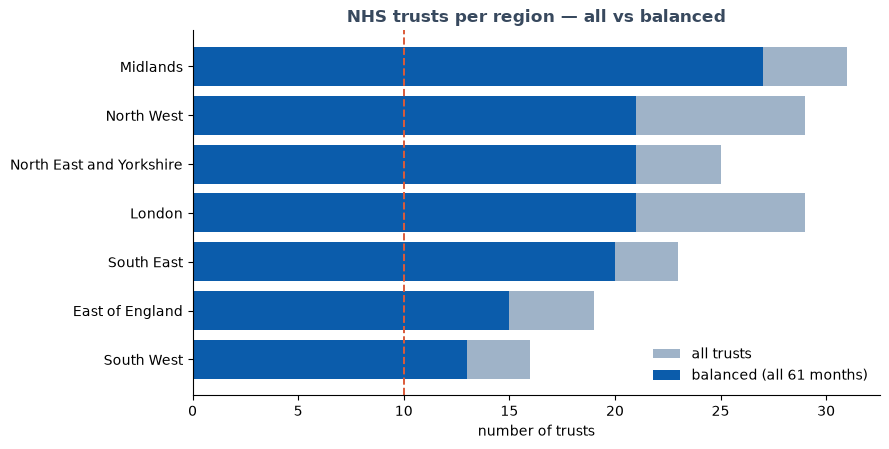

In [5]:
BLUE, GREY, INK = '#0B5CAB', '#9FB3C8', '#38495E'
p = per_region.sort_values('balanced')
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(p.index, p['trusts'], color=GREY, label='all trusts')
ax.barh(p.index, p['balanced'], color=BLUE, label='balanced (all 61 months)')
ax.axvline(10, color='#DC5B39', lw=1.4, ls='--')
ax.set_title('NHS trusts per region — all vs balanced', fontweight='bold', color=INK)
ax.set_xlabel('number of trusts'); ax.legend(loc='lower right', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(FIGS / '00_trusts_per_region.png', dpi=140, bbox_inches='tight')
print('saved', FIGS / '00_trusts_per_region.png'); plt.show()

## Cell 5 — save the lookups

`trust_region_lookup.csv` is what Step 4 consumes; `icb_region_lookup.csv` is the cached ICB table.

In [6]:
trust_region.sort_values(['region', 'branch']).to_csv(RESULTS / 'trust_region_lookup.csv', index=False)
print('wrote', RESULTS / 'trust_region_lookup.csv', 'and', CACHE.name)

wrote /Users/nileshsarkar/Documents/FedOPD/notebooks/eda/results/trust_region_lookup.csv and icb_region_lookup.csv


## Findings

- All **42 current ICBs resolved** to exactly the **7 official NHS England regions** via ODS (0 unresolved);
  every one of the 172 trusts gets a region.
- **Balanced trusts per region all clear the ≥10 bar**, so the 7×10×10 panel is feasible in every region
  (see `meets_10` column / dashed line in the figure).
- Region tier now attached authoritatively → **Step 4 (selection)** is unblocked.

Note: region comes from the trust's *parent ICB* (`Provider Parent`), which is the standard NHS attribution.